Tamaño: (562, 632)
Valores encontrados: [  0 255]


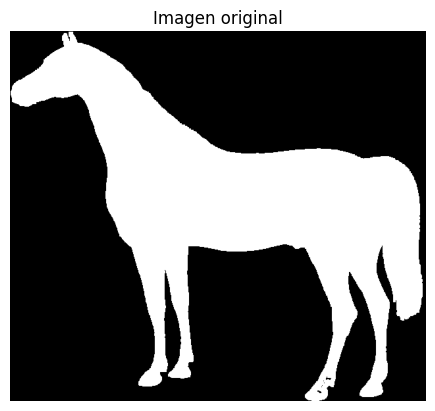

In [1]:
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt


# 1. Cargar imagen GIF
ruta = input("Introduce la ruta del GIF: ")

imagen = Image.open(ruta)
imagen.seek(0)
imagen = imagen.convert("L")

matriz = np.array(imagen)

# Binarizar
_, matriz = cv2.threshold(
    matriz, 127, 255, cv2.THRESH_BINARY
)

print("Tamaño:", matriz.shape)
print("Valores encontrados:", np.unique(matriz))


# 2. Mostrar imagen original
plt.imshow(matriz, cmap="gray")
plt.title("Imagen original")
plt.axis("off")
plt.show()

In [20]:
# 3. Obtener el contorno
def obtener_contorno(imagen):

    contornos, _ = cv2.findContours(
        imagen.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_NONE
    )

    if not contornos:
        return None

    contorno = max(contornos, key=cv2.contourArea)
    puntos = contorno.reshape(-1, 2)

    # Asegurar recorrido horario
    area = cv2.contourArea(contorno, oriented=True)

    if area < 0:
        puntos = puntos[::-1]

    # Inicio: punto superior y más a la izquierda
    indice_inicio = min(
        range(len(puntos)),
        key=lambda i: (puntos[i][1], puntos[i][0])
    )

    puntos = np.roll(puntos, -indice_inicio, axis=0)

    return puntos


puntos = obtener_contorno(matriz)

if puntos is None:
    raise ValueError("No se encontró ningún objeto blanco.")

print("\nPíxeles del contorno:", len(puntos))


# 4. Obtener código Freeman F8

direcciones = {
    (1, 0): 0,
    (1, 1): 1,
    (0, 1): 2,
    (-1, 1): 3,
    (-1, 0): 4,
    (-1, -1): 5,
    (0, -1): 6,
    (1, -1): 7
}


def obtener_f8(puntos):

    cadena = []
    n = len(puntos)

    for i in range(n):

        x1, y1 = puntos[i]
        x2, y2 = puntos[(i + 1) % n]

        dx = int(x2 - x1)
        dy = int(y2 - y1)

        dx = 0 if dx == 0 else (1 if dx > 0 else -1)
        dy = 0 if dy == 0 else (1 if dy > 0 else -1)

        if (dx, dy) not in direcciones:
            raise ValueError(f"Movimiento inválido: {(dx, dy)}")

        cadena.append(direcciones[(dx, dy)])

    return cadena


cadena = obtener_f8(puntos)


# 5. Obtener código AAF8


# 5. Obtener código AAF8

def obtener_aaf8(cadena):

    n = len(cadena)

    if n == 0:
        return []

    aaf8 = []

    for i in range(n):

        # Dirección siguiente (vector de cambio)
        siguiente = cadena[(i + 1) % n]

        # Si la dirección no cambia, se asigna el símbolo 8
        if siguiente == cadena[i]:
            aaf8.append(8)
            continue

        # Buscar la dirección de referencia hacia atrás.
        # La búsqueda es circular para contemplar el cierre
        # de la cadena.
        referencia = None

        for desplazamiento in range(1, n):
            k = (i - desplazamiento) % n

            if cadena[k] != cadena[i]:
                referencia = cadena[k]
                break

        if referencia is None:
            raise ValueError(
                "No se encontró una dirección de referencia válida."
            )

        # Calcular el ángulo relativo módulo 8
        simbolo = (siguiente - referencia) % 8

        aaf8.append(simbolo)

    return aaf8


# Obtener AAF8
aaf8 = obtener_aaf8(cadena)


# 6. Mostrar resultados

print("\nCódigo Freeman F8:")
print(''.join(map(str, cadena)))
print("Longitud F8:", len(cadena))

print("\nCódigo AAF8:")
print(''.join(map(str, aaf8)))
print("Longitud AAF8:", len(aaf8))


Píxeles del contorno: 3359

Código Freeman F8:
0000002221121122121221100000010100010001010101001010101110010101011101021010101010210101101102111211110111021121121011111121121212121101010100210121211022111021012111112101101111210110111011111012101210021000021001102100210002100102110111111010101111111100110110011001010010010100001000000010000000010000000000000000000000700010000000070000000000007000000700000000700000007000000007000000000000007000000000000000007000001000000000000000100000000010010000100010001001001000210011000110001700000000700070000000000070000000000001001001002110001110102100112101111221022102211212221122121222212221222212222122222222221222222222222222223212223122232221222321222322222222222322222222222222222222222222222122222211222222222222212122231122232122222222222222222222323222222222322232232222444332443434443243243444532244454666565444656667665666666666666665322444666666666665666656666566566566565665566665665665666566666566666665665666756666666666653232323223223222

In [21]:

# PRUEBA 1: Ejemplo del artículo

f8_prueba = [
    0, 0, 0, 2, 2, 1, 2, 3, 3, 4, 4,
    4, 5, 6, 0, 0, 7, 5, 4, 6, 7
]

aaf8_esperado = [
    8, 8, 3, 8, 1, 0, 2, 8, 2, 8, 8,
    2, 2, 3, 8, 1, 5, 5, 1, 3, 2
]

aaf8_obtenido = obtener_aaf8(f8_prueba)

print("F8 del artículo:")
print(''.join(map(str, f8_prueba)))

print("\nAAF8 esperado:")
print(''.join(map(str, aaf8_esperado)))

print("\nAAF8 obtenido:")
print(''.join(map(str, aaf8_obtenido)))

print("\n¿Los resultados coinciden?")
print(aaf8_obtenido == aaf8_esperado)


F8 del artículo:
000221233444560075467

AAF8 esperado:
883810282882238155132

AAF8 obtenido:
883810282882238155132

¿Los resultados coinciden?
True
